# ORCHID tutorial 03: Master equation and the EGDM

**Goals.** Solve the master equation (ME) for the mobility, compare it with KMC, and reproduce the
extended Gaussian disorder model (EGDM) of Pasveer *et al.* (PRL 94, 206601, 2005).

### Theory
In steady state, $\sum_j [W_{ij}p_i(1-p_j) - W_{ji}p_j(1-p_i)]=0$. Linearising around Fermi–Dirac
occupations $f_i$ gives a resistor network with conductances

$$G_{ij} = \frac{e^2}{k_BT}\,W_{ij}\,f_i(1-f_j),$$

solved by preconditioned CG. The EGDM factorises the mobility as
$\mu(T,p,F)=\mu_0(T)\,g_1(p,T)\,g_2(F,T)$ with $\mu_0(T)=c_1\frac{a^2\nu_0 e}{\sigma}e^{-c_2\hat\sigma^2}$,
$c_1=1.8\times10^{-9}$, $c_2=0.42$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


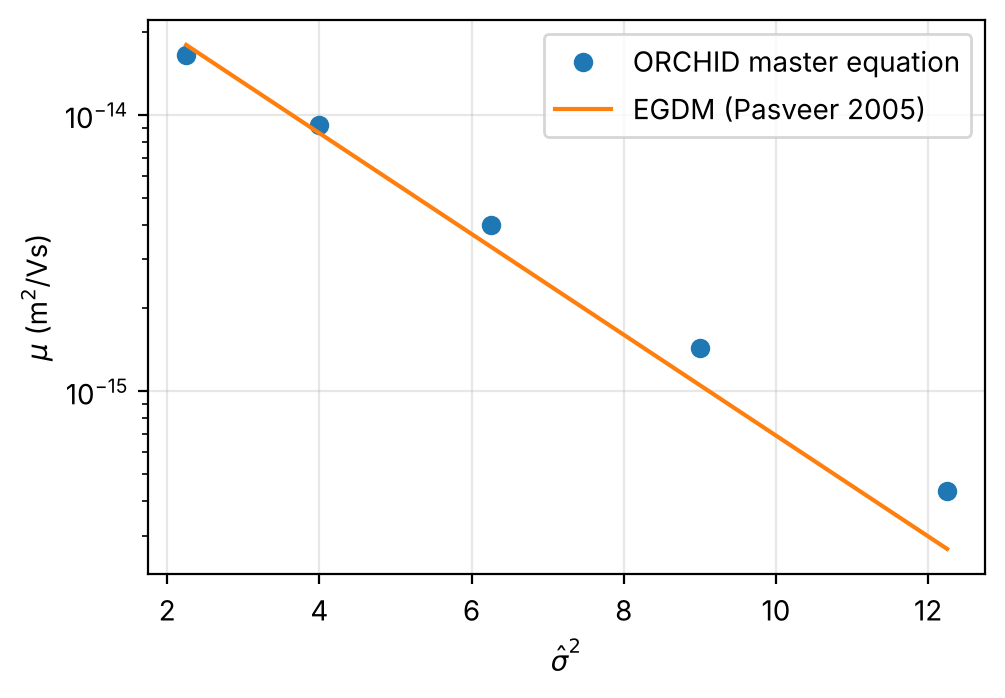

In [2]:
from orchid.lattice import Lattice
from orchid.master_equation import me_linear_response
from orchid.kmc import mobility_independent
from orchid.models import egdm_pasveer
from orchid.constants import kB_eV
sigma, a = 0.1, 1.6e-9
shats = np.array([1.5, 2.0, 2.5, 3.0, 3.5])
mu_me, mu_eg = [], []
for sh in shats:
    T = sigma / (sh * kB_eV)
    lat = Lattice(24, a=a, seed=1).set_disorder(sigma)
    mu_me.append(me_linear_response(lat, T, 1e-7, alpha=10.0)[0])
    mu_eg.append(egdm_pasveer(T, 1e-7, 0.0, sigma, a, nu0=1e12))
plt.semilogy(shats**2, mu_me, "o", label="ORCHID master equation")
plt.semilogy(shats**2, mu_eg, "-", label="EGDM (Pasveer 2005)")
plt.xlabel(r"$\hat\sigma^2$"); plt.ylabel(r"$\mu$ (m$^2$/Vs)"); plt.legend();

Both curves are close to straight lines in $\hat\sigma^2$. Now cross-check the ME against KMC at one temperature:

In [3]:
T = sigma / (2.5 * kB_eV)
lat = Lattice(24, a=a, seed=1).set_disorder(sigma)
me = me_linear_response(lat, T, 1e-7, alpha=10.0)[0]
kmc, err = mobility_independent(lat, T, 0.05 * sigma, alpha=10.0, n_carriers=64, n_eq=100000, n_meas=300000)
print(f"ME {me:.3e}   KMC {kmc:.3e} +- {err:.1e}   ratio {kmc/me:.3f}")

ME 4.004e-15   KMC 4.057e-15 +- 4.5e-17   ratio 1.013


### Density dependence and the Einstein relation

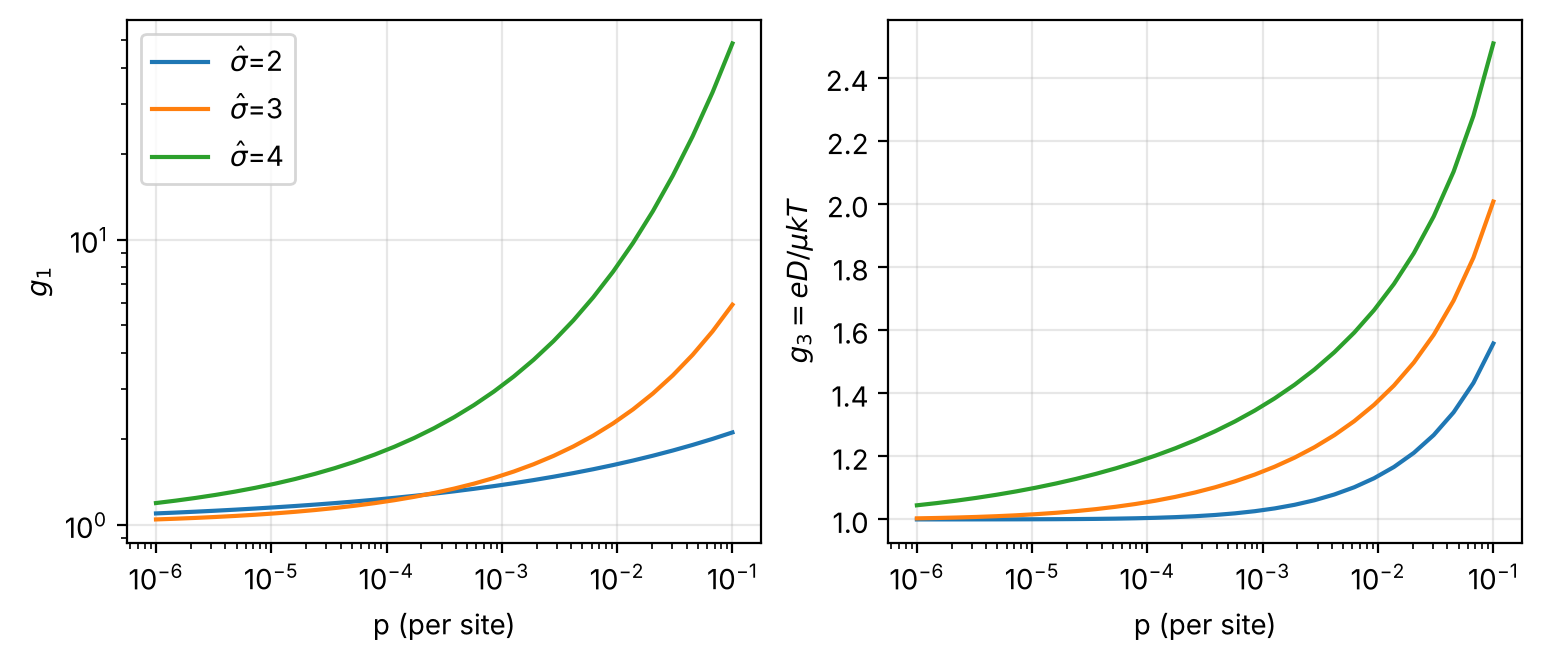

In [4]:
from orchid.models import egdm_g1, einstein_ratio_gaussian
p = np.logspace(-6, -1, 30)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for sh in (2, 3, 4):
    T = sigma / (sh * kB_eV)
    ax[0].loglog(p, egdm_g1(p, T, sigma), label=rf"$\hat\sigma$={sh}")
    ax[1].semilogx(p, [einstein_ratio_gaussian(x, T, sigma) for x in p], label=rf"$\hat\sigma$={sh}")
ax[0].set_xlabel("p (per site)"); ax[0].set_ylabel("$g_1$"); ax[0].legend()
ax[1].set_xlabel("p (per site)"); ax[1].set_ylabel(r"$g_3=eD/\mu kT$");

**Exercise.** Use `orchid.master_equation.me_linear_response` at three densities $p=10^{-5},10^{-3},10^{-2}$ for $\hat\sigma=3$ and compare with `egdm_g1`.

<details><summary>Solution</summary>

```python
T = sigma/(3*kB_eV); lat = Lattice(24, a=a, seed=1).set_disorder(sigma)
m0 = me_linear_response(lat, T, 1e-7)[0]
for p in (1e-5, 1e-3, 1e-2):
    print(p, me_linear_response(lat, T, p)[0]/m0, egdm_g1(p, T, sigma))
```
The two agree to within tens of percent (V2).
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("03", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 03`.

In [5]:
from orchid.tutorials import quiz
quiz("03")

Quiz 03: Master equation and the EGDM

Q1. In linear response, the master equation maps onto which problem?
    (a) An eigenvalue problem
    (b) A random walk with absorbing boundaries
    (c) A resistor network with conductances G_ij proportional to W_ij f_i (1 - f_j)
    (d) A Poisson equation

Q2. What causes the density enhancement g1(p) of the EGDM?
    (a) Field-assisted hopping
    (b) Filling of deep tail states, which raises the effective transport level
    (c) Coulomb repulsion
    (d) Higher temperature

Q3. In Pasveer's parametrisation mu0(T) = mu_00 exp(-c2 sigma-hat^2), c2 is approximately
    (a) 0.42
    (b) 0.11
    (c) 4/9 = 0.44 exactly
    (d) 1

Q4. Why is the ME much cheaper than KMC for the zero-field mobility?
    (a) It uses a smaller lattice
    (b) It runs on the GPU only
    (c) It solves one sparse linear system and has no stochastic noise
    (d) It ignores disorder

Q5. For a Gaussian DOS at high density, the generalised Einstein ratio g3 = eD/(mu kT) i

In [6]:
# replace with your answers, e.g. "abcda"
# quiz("03", answers=".....")

<details><summary>Answer key</summary>

`cbacb`. Run `quiz("03", answers="cbacb")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`